<a href="https://colab.research.google.com/github/therafaeliger/klastik/blob/main/KLASTIK_v1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Library

In [ ]:
import os
import re
import cv2
import numpy as np
import matplotlib.pyplot as plt
import pickle
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from skimage.feature import hog, local_binary_pattern
from imblearn.over_sampling import SMOTE
from google.colab import drive

## Data (from Google Drive)

In [ ]:
drive.mount('/content/drive')
folder_path = '/content/drive/MyDrive/Datasets/dataset-plastic'
use_feature = 'all_combined'  # options: 'hog', 'lbp', 'hog+color', 'hog+lbp', 'all_combined', etc.

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Preprocessing Data

In [ ]:
# Label
def get_label_from_filename(filename):
    name = os.path.splitext(filename)[0]
    label = re.split(r'\d+', name)[0]
    return label.lower()

# Preprocessing
def preprocess_image(image_path):
    image = cv2.imread(image_path)
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    resized = cv2.resize(gray, (128, 128))
    eq = cv2.equalizeHist(resized)
    blur = cv2.GaussianBlur(eq, (5, 5), 0)
    return blur

## Feature Extraction and Selection

### Feature Extraction

In [ ]:
def extract_hog_features(image):
    features, _ = hog(image, orientations=9, pixels_per_cell=(8, 8),
                      cells_per_block=(2, 2), visualize=True, channel_axis=None)
    return features

def extract_color_hist(image, bins=(8, 8, 8)):
    resized = cv2.resize(image, (128, 128))  # ensure fixed size
    hist = cv2.calcHist([resized], [0, 1, 2], None, bins,
                        [0, 256, 0, 256, 0, 256])
    return cv2.normalize(hist, hist).flatten()

def extract_lbp_features(gray_image, P=8, R=1, method='uniform'):
    lbp = local_binary_pattern(gray_image, P, R, method)
    (hist, _) = np.histogram(lbp.ravel(),
                             bins=np.arange(0, P + 3),
                             range=(0, P + 2))
    hist = hist.astype("float")
    hist /= (hist.sum() + 1e-6)
    return hist

### Feature Selection

In [ ]:
def extract_features(image_path, mode='hog'):
    gray_image = preprocess_image(image_path)
    color_image = None
    if 'color' in mode or mode == 'all_combined':
        color_image = cv2.imread(image_path)
        if color_image is None:
            raise ValueError(f"Could not read color image: {image_path}")

    if mode == 'hog':
        return extract_hog_features(gray_image)
    elif mode == 'color':
        if color_image is None: color_image = cv2.imread(image_path)
        return extract_color_hist(color_image)
    elif mode == 'lbp':
        return extract_lbp_features(gray_image)
    elif mode == 'hog+color':
        if color_image is None: color_image = cv2.imread(image_path)
        return np.hstack([
            extract_hog_features(gray_image),
            extract_color_hist(color_image)
        ])
    elif mode == 'hog+lbp':
        return np.hstack([
            extract_hog_features(gray_image),
            extract_lbp_features(gray_image)
        ])
    elif mode == 'all_combined':
        if color_image is None: color_image = cv2.imread(image_path)
        return np.hstack([
            extract_hog_features(gray_image).flatten(),
            extract_color_hist(color_image).flatten(),
            extract_lbp_features(gray_image).flatten(),
        ])
    else:
        raise ValueError(f"Unsupported feature mode: {mode}")

## Load Data

In [ ]:
features, labels = [], []
image_files = [f for f in os.listdir(folder_path) if f.endswith(('.png', '.jpg', '.jpeg'))]

for fname in image_files:
    label = get_label_from_filename(fname)
    full_path = os.path.join(folder_path, fname)
    feat = extract_features(full_path, mode=use_feature)
    features.append(feat)
    labels.append(label)

# print(features)
# print(labels)

### Plotting

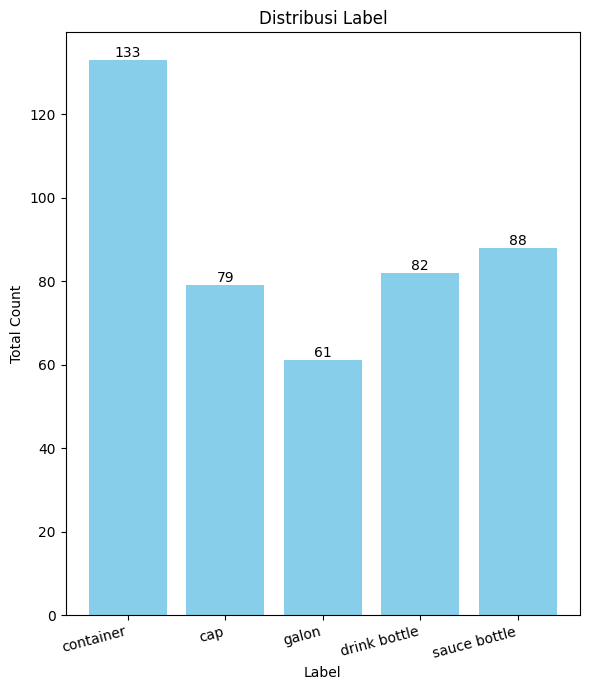

Exact total value for each label:
=> container: 133
=> cap: 79
=> galon: 61
=> drink bottle: 82
=> sauce bottle: 88


In [ ]:
# Labels Distribution
label_counts = {}
for label in labels:
    label_counts[label] = label_counts.get(label, 0) + 1

# Plotting Data
labels_plot = list(label_counts.keys())
counts_plot = list(label_counts.values())

plt.figure(figsize=(6, 7))
bars = plt.bar(labels_plot, counts_plot, color='skyblue')
plt.xlabel('Label')
plt.ylabel('Total Count')
plt.title('Distribusi Label')
plt.xticks(rotation=15, ha='right')
plt.tight_layout()

for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval , int(yval), ha='center', va='bottom')

plt.show()

# Addition
print("Exact total value for each label:")
for label, count in label_counts.items():
    print(f"=> {label}: {count}")

## Train/Test Split

In [ ]:
# Encode Labels
le = LabelEncoder()
y = le.fit_transform(labels)
X_original = np.array(features)

# Ensure X_original is 2D
if X_original.ndim == 1:
    X_original = np.vstack(X_original).T # Stack and transpose if needed

# Train/Test Split
X_train_orig, X_test_orig, y_train, y_test = train_test_split(X_original, y, stratify=y, test_size=0.2, random_state=42)

# Scaling Features
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train_orig)
X_test = scaler.transform(X_test_orig)

unique_labels_in_test = np.unique(y_test)
target_names_in_test = le.inverse_transform(unique_labels_in_test)

# Handle Imbalanced Data (for training)
smote = SMOTE(random_state=42)
X_train_bal, y_train_bal = smote.fit_resample(X_train, y_train)

### Plotting

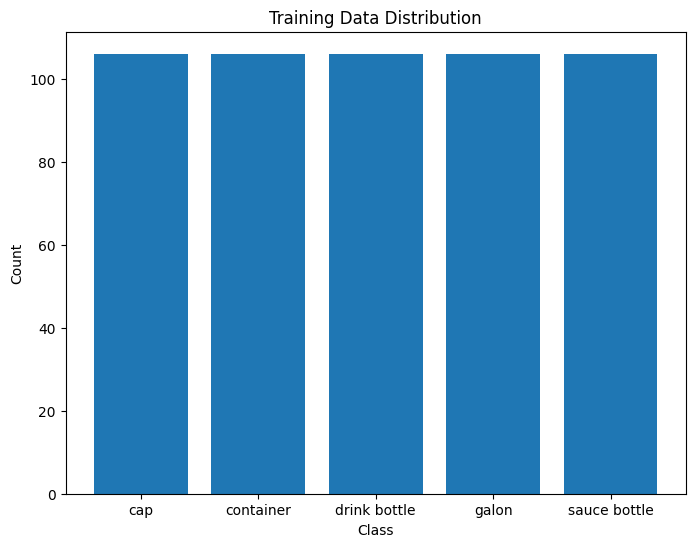

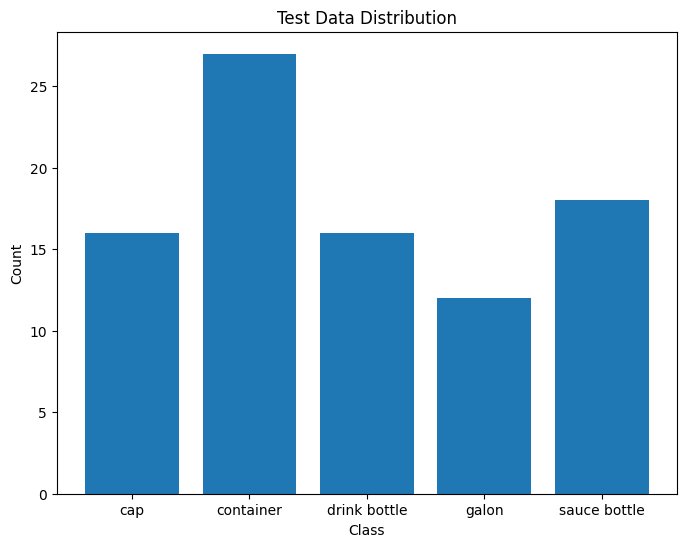

In [ ]:
def plot_distribution(y_data, title, le):
    unique_labels, counts = np.unique(y_data, return_counts=True)
    labels = le.inverse_transform(unique_labels)
    plt.figure(figsize=(8, 6))
    plt.bar(labels, counts)
    plt.title(title)
    plt.xlabel("Class")
    plt.ylabel("Count")
    plt.show()

plot_distribution(y_train_bal, "Training Data Distribution", le)
plot_distribution(y_test, "Test Data Distribution", le)

## Model ML

In [ ]:
models_to_tune = {
    # "SVM (Linear)": (SVC(probability=True), {
    #     'kernel': ['linear'],
    #     'C': [0.1, 1, 10, 100]
    # }),
    # "SVM (RBF)": (SVC(probability=True), {
    #     'kernel': ['rbf'],
    #     'C': [0.1, 1, 10, 100],
    #     'gamma': [0.001, 0.01, 0.1, 1, 'scale', 'auto']
    # }),
    "Random Forest": (RandomForestClassifier(random_state=42), {
        'n_estimators': [50, 100, 200],
        'max_depth': [None, 10, 20, 30],
        'min_samples_split': [2, 5, 10],
        'min_samples_leaf': [1, 2, 4]
    }),
    # "KNN": (KNeighborsClassifier(), {
    #     'n_neighbors': [3, 5, 7, 9],
    #     'weights': ['uniform', 'distance'],
    #     'metric': ['euclidean', 'manhattan', 'minkowski']
    # })
}

## Training dan Evaluasi Model



Tuning and Evaluating model: Random Forest
Fitting 5 folds for each of 108 candidates, totalling 540 fits
Best parameters for Random Forest: {'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 200}
Best cross-validation accuracy for Random Forest: 0.9038

Test Accuracy for Random Forest (with best params): 0.7753
              precision    recall  f1-score   support

         cap       0.81      0.81      0.81        16
   container       0.70      0.96      0.81        27
drink bottle       0.67      0.50      0.57        16
       galon       0.83      0.83      0.83        12
sauce bottle       1.00      0.67      0.80        18

    accuracy                           0.78        89
   macro avg       0.80      0.76      0.77        89
weighted avg       0.79      0.78      0.77        89



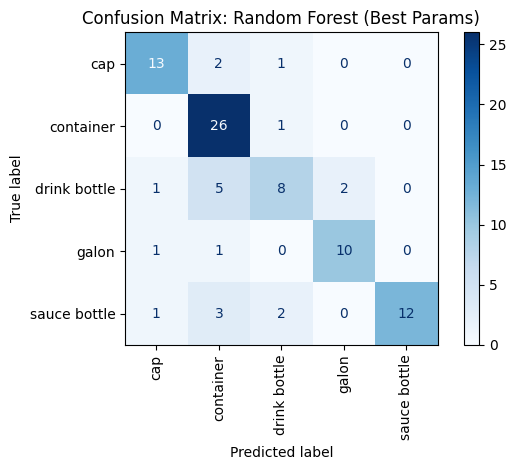

In [ ]:
best_models = {}

for name, (model, params) in models_to_tune.items():
    print(f"\n\nTuning and Evaluating model: {name}")
    grid_search = GridSearchCV(model, params, cv=5, scoring='accuracy', n_jobs=-1, verbose=1)
    # grid_search.fit(X_train, y_train)
    grid_search.fit(X_train_bal, y_train_bal)

    print(f"Best parameters for {name}: {grid_search.best_params_}")
    print(f"Best cross-validation accuracy for {name}: {grid_search.best_score_:.4f}")

    best_model = grid_search.best_estimator_
    best_models[name] = best_model

    y_pred = best_model.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    print(f"\nTest Accuracy for {name} (with best params): {acc:.4f}")

    # Dapatkan unique labels dari y_test yang sudah diencode dan target names yang sesuai
    current_unique_labels_in_test = np.unique(y_test)
    current_target_names_in_test = le.inverse_transform(current_unique_labels_in_test)

    print(classification_report(y_test, y_pred, labels=current_unique_labels_in_test, target_names=current_target_names_in_test, zero_division=0))

    cm = confusion_matrix(y_test, y_pred, labels=current_unique_labels_in_test)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=current_target_names_in_test)
    disp.plot(xticks_rotation='vertical', cmap='Blues')
    plt.title(f"Confusion Matrix: {name} (Best Params)")
    plt.tight_layout()
    plt.show()

## Save Model as PKL

In [ ]:
save_model_path = "best_model.pkl"
save_scaler_path = "scaler.pkl"
save_encoder_path = "label_encoder.pkl"

with open(save_model_path, 'wb') as f:
    pickle.dump(best_model, f)
with open(save_scaler_path, 'wb') as f:
    pickle.dump(scaler, f)
with open(save_encoder_path, 'wb') as f:
    pickle.dump(le, f)

## Prediction Mode

In [ ]:
def load_model_components():
    with open(save_model_path, 'rb') as f:
        model = pickle.load(f)
    with open(save_scaler_path, 'rb') as f:
        scaler = pickle.load(f)
    with open(save_encoder_path, 'rb') as f:
        le = pickle.load(f)
    return model, scaler, le

def predict_new_image(image_path, model, scaler, le, mode='all_combined'):
    feat = extract_features(image_path, mode=mode).reshape(1, -1)
    feat_scaled = scaler.transform(feat)
    pred_encoded = model.predict(feat_scaled)[0]
    label = le.inverse_transform([pred_encoded])[0]
    return label

# Example usage
model, scaler, le = load_model_components()
image_path = "/content/drive/MyDrive/Datasets/new-dataset-plastic/cap100.jpg"
predicted_label = predict_new_image(image_path, model, scaler, le, mode='all_combined')
print(f"Predicted: {predicted_label}")

Predicted: cap


--------------------------------------------------------------------------------

In [ ]:
def preprocess_and_segment(image_path):
    # 1. Baca gambar
    img = cv2.imread(image_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)  # Konversi ke RGB
    original = img.copy()

    # 2. Preprocessing: Gaussian Blur
    blurred = cv2.GaussianBlur(img, (7, 7), 0)

    # 3. Deteksi tepi dengan Canny
    gray = cv2.cvtColor(blurred, cv2.COLOR_RGB2GRAY)
    edges = cv2.Canny(gray, 50, 150)

    # 4. Segmentasi Watershed
    # Thresholding untuk mendapatkan area pasti foreground
    _, thresh = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)

    # Operasi morfologi untuk menghilangkan noise kecil
    kernel = np.ones((3, 3), np.uint8)
    opening = cv2.morphologyEx(thresh, cv2.MORPH_OPEN, kernel, iterations=2)

    # Area pasti background
    sure_bg = cv2.dilate(opening, kernel, iterations=3)

    # Transformasi jarak untuk mendapatkan area pasti foreground
    dist_transform = cv2.distanceTransform(opening, cv2.DIST_L2, 5)
    _, sure_fg = cv2.threshold(dist_transform, 0.7 * dist_transform.max(), 255, 0)
    sure_fg = np.uint8(sure_fg)

    # Area yang tidak diketahui (region boundary)
    unknown = cv2.subtract(sure_bg, sure_fg)

    # Labeling markers
    _, markers = cv2.connectedComponents(sure_fg)
    markers = markers + 1
    markers[unknown == 255] = 0

    # Terapkan Watershed
    markers = cv2.watershed(img, markers)
    img[markers == -1] = [255, 0, 0]  # Garis batas segmentasi

    # 5. Plot hasil
    plt.figure(figsize=(15, 10))

    plt.subplot(2, 3, 1)
    plt.title('Original Image')
    plt.imshow(original)
    plt.axis('off')

    plt.subplot(2, 3, 2)
    plt.title('Gaussian Blur')
    plt.imshow(blurred)
    plt.axis('off')

    plt.subplot(2, 3, 3)
    plt.title('Canny Edges')
    plt.imshow(edges, cmap='gray')
    plt.axis('off')

    plt.subplot(2, 3, 4)
    plt.title('Sure Foreground')
    plt.imshow(sure_fg, cmap='gray')
    plt.axis('off')

    plt.subplot(2, 3, 5)
    plt.title('Markers')
    plt.imshow(markers, cmap='jet')
    plt.axis('off')

    plt.subplot(2, 3, 6)
    plt.title('Watershed Result')
    plt.imshow(img)
    plt.axis('off')

    plt.tight_layout()
    plt.show()

In [ ]:
# Contoh penggunaan
image_path1 = "/content/drive/MyDrive/splitted_dataset/train/plastic/plastic10.jpg"  # Ganti dengan path gambar Anda
preprocess_and_segment(image_path1)

image_path2 = "/content/drive/MyDrive/splitted_dataset/train/plastic/plastic100.jpg"  # Ganti dengan path gambar Anda
preprocess_and_segment(image_path2)


## Ekstraksi Fitur

### Shape Features

In [ ]:
def extract_shape_features(image_path):
    # 1. Baca gambar
    img = cv2.imread(image_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)  # Konversi ke RGB
    original = img.copy()

    # 2. Preprocessing: Gaussian Blur
    blurred = cv2.GaussianBlur(img, (5, 5), 0)

    # 3. Deteksi tepi dengan Canny
    gray = cv2.cvtColor(blurred, cv2.COLOR_RGB2GRAY)
    edges = cv2.Canny(gray, 50, 150)

    # 4. Segmentasi Watershed
    # Thresholding untuk mendapatkan area pasti foreground
    _, thresh = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)

    # Operasi morfologi untuk menghilangkan noise kecil
    kernel = np.ones((3, 3), np.uint8)
    opening = cv2.morphologyEx(thresh, cv2.MORPH_OPEN, kernel, iterations=2)

    # Area pasti background
    sure_bg = cv2.dilate(opening, kernel, iterations=3)

    # Transformasi jarak untuk mendapatkan area pasti foreground
    dist_transform = cv2.distanceTransform(opening, cv2.DIST_L2, 5)
    _, sure_fg = cv2.threshold(dist_transform, 0.7 * dist_transform.max(), 255, 0)
    sure_fg = np.uint8(sure_fg)

    # Area yang tidak diketahui (region boundary)
    unknown = cv2.subtract(sure_bg, sure_fg)

    # Labeling markers
    _, markers = cv2.connectedComponents(sure_fg)
    markers = markers + 1
    markers[unknown == 255] = 0

    # Terapkan Watershed
    markers = cv2.watershed(img, markers)
    img[markers == -1] = [255, 0, 0]  # Garis batas segmentasi

    # 2. Ekstrak kontur dari markers
    mask = np.zeros(gray.shape, dtype=np.uint8)
    mask[markers == -1] = 255  # Ambil batas watershed
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    contour_only_image = np.zeros_like(original)
    cv2.drawContours(contour_only_image, contours, -1, (0, 255, 0), 2)
    # 3. Hitung fitur untuk setiap kontur
    features = []
    for cnt in contours:
        if cv2.contourArea(cnt) > 100:  # Abaikan kontur kecil
            # Fitur dasar
            area = cv2.contourArea(cnt)
            perimeter = cv2.arcLength(cnt, True)

            # Rasio aspek
            x, y, w, h = cv2.boundingRect(cnt)
            aspect_ratio = float(w) / h

            # Soliditas
            hull = cv2.convexHull(cnt)
            hull_area = cv2.contourArea(hull)
            solidity = float(area) / hull_area if hull_area > 0 else 0

            # Ekstensitas
            rect_area = w * h
            extent = float(area) / rect_area

            # Momen Hu
            moments = cv2.moments(cnt)
            hu_moments = cv2.HuMoments(moments)

            # Bentuk convex hull vs kontur
            convexity_defects = cv2.convexityDefects(cnt, cv2.convexHull(cnt, returnPoints=False))

            features.append({
                'area': area,
                'perimeter': perimeter,
                'aspect_ratio': aspect_ratio,
                'solidity': solidity,
                'extent': extent,
                'hu_moments': hu_moments,
                'convexity_defects': convexity_defects
            })

    # 4. Visualisasi
    output = img.copy()
    cv2.drawContours(output, contours, -1, (0, 255, 0), 2)

    plt.figure(figsize=(12, 6))
    plt.subplot(1, 2, 1)
    plt.title('Original Image')
    plt.imshow(img)
    plt.axis('off')

    plt.subplot(1, 2, 2)
    plt.title('Detected Contours')
    plt.imshow(contour_only_image)
    plt.axis('off')

    plt.tight_layout()
    plt.show()

    return features

### Robert Cross Edge Detection

In [ ]:
def roberts_cross_edge_detection(image_path, threshold = 50):

    # Convert the image to grayscale
    img = cv2.imread(image_path)
    gray_image = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    # Apply Roberts Cross kernels
    kernel_x = np.array([[1, 0],
                         [0, -1]])
    kernel_y = np.array([[0, 1],
                         [-1, 0]])

    # Convolve the image with the kernels
    horizontal_edges = cv2.filter2D(gray_image, -1, kernel_x)
    vertical_edges = cv2.filter2D(gray_image, -1, kernel_y)

    # Ensure both arrays have the same data type
    horizontal_edges = np.float32(horizontal_edges)
    vertical_edges = np.float32(vertical_edges)

    # Compute gradient magnitude
    gradient_magnitude = cv2.magnitude(horizontal_edges, vertical_edges)

    # Apply thresholding to highlight edges
    _, edges = cv2.threshold(gradient_magnitude, threshold, 255, cv2.THRESH_BINARY)

    plt.figure(figsize=(10, 5))

    # Original Image
    # plt.subplot(1, 2, 1)
    # plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    # plt.title('Original Image')
    # plt.axis('off')

    # # Detected Edges
    # plt.subplot(1, 2, 2)
    # plt.imshow(edges, cmap='gray')
    # plt.title('Roberts Cross Edge Detection with Thresholding')
    # plt.axis('off')

    # plt.show()
    return edges

In [ ]:
# # Contoh penggunaan

# features = extract_shape_features(image_path1)

# # Cetak fitur untuk objek pertama
# print("Shape Features:")
# print(f"- Area: {features[0]['area']} pixels")
# print(f"- Perimeter: {features[0]['perimeter']} pixels")
# print(f"- Aspect Ratio: {features[0]['aspect_ratio']:.2f}")
# print(f"- Solidity: {features[0]['solidity']:.2f}")
# print(f"- Extent: {features[0]['extent']:.2f}")
# print(f"- Hu Moments: {features[0]['hu_moments']}")


features2 = extract_shape_features(image_path2)

# Cetak fitur untuk objek pertama
print("Shape Features:")
print(f"- Area: {features2[0]['area']} pixels")
print(f"- Perimeter: {features2[0]['perimeter']} pixels")
print(f"- Aspect Ratio: {features2[0]['aspect_ratio']:.2f}")
print(f"- Solidity: {features2[0]['solidity']:.2f}")
print(f"- Extent: {features2[0]['extent']:.2f}")
print(f"- Hu Moments: {features2[0]['hu_moments']}")

In [ ]:
features = roberts_cross_edge_detection(image_path2, 5)
featuresflat = features.flatten()
print(type(featuresflat), '\t', featuresflat.shape, 't', featuresflat)

### Transparent Plastic

In [ ]:
def segment_transparent_plastic(image_path):
    # 1. Baca gambar dengan background kontras (hitam/putih)
    img = cv2.imread(image_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    original = img.copy()

    # 2. Konversi ke HSV dan ambil Value channel (untuk deteksi refleksi)
    hsv = cv2.cvtColor(img, cv2.COLOR_RGB2HSV)
    value = hsv[:, :, 2]

    # 3. Thresholding adaptif untuk menangkap refleksi
    thresh = cv2.adaptiveThreshold(
        value, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
        cv2.THRESH_BINARY_INV, 11, 2
    )

    # 4. Operasi morfologi untuk membersihkan noise
    kernel = np.ones((3, 3), np.uint8)
    cleaned = cv2.morphologyEx(thresh, cv2.MORPH_OPEN, kernel, iterations=2)

    # 5. Deteksi kontur
    contours, _ = cv2.findContours(cleaned, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    # 6. Filter kontur berdasarkan area
    min_area = 500  # Sesuaikan dengan ukuran sampah
    plastic_contours = [cnt for cnt in contours if cv2.contourArea(cnt) > min_area]

    # 7. Gambar bounding box
    output = original.copy()
    for cnt in plastic_contours:
        x, y, w, h = cv2.boundingRect(cnt)
        cv2.rectangle(output, (x, y), (x + w, y + h), (0, 255, 0), 2)

    # 8. Visualisasi
    plt.figure(figsize=(15, 10))
    plt.subplot(2, 2, 1)
    plt.title("Original Image")
    plt.imshow(original)
    plt.axis('off')

    plt.subplot(2, 2, 2)
    plt.title("Value Channel (HSV)")
    plt.imshow(value, cmap='gray')
    plt.axis('off')

    plt.subplot(2, 2, 3)
    plt.title("Thresholded Reflections")
    plt.imshow(thresh, cmap='gray')
    plt.axis('off')

    plt.subplot(2, 2, 4)
    plt.title("Detected Plastic")
    plt.imshow(output)
    plt.axis('off')

    plt.tight_layout()
    plt.show()

In [ ]:
# Contoh penggunaan
image_path = "/content/drive/My Drive/Pattern Recognition/plastic/plastic3.jpg"
segment_transparent_plastic(image_path)

###Model Train

In [ ]:
!unzip dataset-sampah.zip

In [ ]:
!mkdir \splitted_dataset

In [ ]:
data_dir = 'drive/MyDrive/splitted_dataset/'
train_dir = os.path.join(data_dir, 'train')
val_dir = os.path.join(data_dir, 'val')

In [ ]:
data = {}
for j, dir_ in enumerate([train_dir, val_dir]):
    features = []
    labels = []
    for category in os.listdir(dir_):
        for img_path in os.listdir(os.path.join(dir_, category)):
            img_path_ = os.path.join(dir_, category, img_path)
            print(img_path_)

            img_features = roberts_cross_edge_detection(img_path_, 5).flatten()


            features.append(img_features)
            labels.append(category)

    data[['training_data', 'validation_data'][j]] = features
    data[['training_labels', 'validation_labels'][j]] = labels

In [ ]:
print(len(data['training_data']))
print(len(data['training_labels']))
print(data['training_labels'][1] ,'\t' , data['training_data'][1])

In [ ]:
# train model

model = RandomForestClassifier(random_state=0)
model.fit(data['training_data'], data['training_labels'])

In [ ]:
# test performance
y_pred = model.predict(data['validation_data'])
score = accuracy_score(y_pred, data['validation_labels'])

print(score)

In [ ]:
# save the model
with open('./model.p', 'wb') as f:
    pickle.dump(model, f)
    f.close()